In [1]:
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score


In [2]:
# Step 2: Load the Digits dataset
digits = load_digits()

X = digits.data
y = digits.target

print("Dataset Loaded Successfully")
print("Original Dataset Shape:", X.shape)
print("Original Number of Features:", X.shape[1])

Dataset Loaded Successfully
Original Dataset Shape: (1797, 64)
Original Number of Features: 64


In [3]:
# Step 3: Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape: (1437, 64)
Testing Data Shape: (360, 64)


In [4]:
# Step 4: Classification using original 64 features
original_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

original_model.fit(X_train, y_train)

y_pred_original = original_model.predict(X_test)

accuracy_original = accuracy_score(y_test, y_pred_original)

print("\nOriginal Features Classification")
print("Number of Features:", X.shape[1])
print("Accuracy:", accuracy_original)


Original Features Classification
Number of Features: 64
Accuracy: 0.9722222222222222


In [5]:
# Step 5: Apply PCA while retaining 95% variance
pca_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("classifier", LogisticRegression(max_iter=2000))
])

pca_model.fit(X_train, y_train)

y_pred_pca = pca_model.predict(X_test)

accuracy_pca = accuracy_score(y_test, y_pred_pca)

# Get number of features after PCA
features_after_pca = pca_model.named_steps["pca"].n_components_

print("\nPCA Classification")
print("Features Before PCA:", X.shape[1])
print("Features After PCA:", features_after_pca)
print("Accuracy:", accuracy_pca)


PCA Classification
Features Before PCA: 64
Features After PCA: 40
Accuracy: 0.9527777777777777


In [6]:
# Step 6: Compare classification performance
print("\nClassification Performance Comparison")

print("Accuracy Before PCA:", accuracy_original)
print("Accuracy After PCA:", accuracy_pca)



Classification Performance Comparison
Accuracy Before PCA: 0.9722222222222222
Accuracy After PCA: 0.9527777777777777



Reduced Dataset Shape for Visualization: (1797, 2)


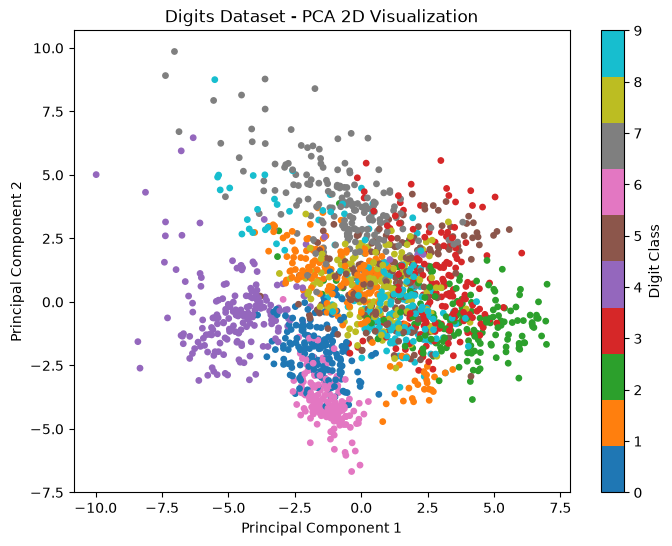

In [7]:
# Step 7: Visualize data in 2 dimensions using PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_scaled)

print("\nReduced Dataset Shape for Visualization:", X_2d.shape)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=y,
    cmap="tab10",
    s=15
)

plt.title("Digits Dataset - PCA 2D Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Digit Class")

plt.show()

In [8]:
# Step 8: Display explained variance
print("\nExplained Variance Ratio of 2 Components:")
print(pca_2d.explained_variance_ratio_)

print(
    "Total Variance Retained:",
    sum(pca_2d.explained_variance_ratio_)
)


Explained Variance Ratio of 2 Components:
[0.12033916 0.09561054]
Total Variance Retained: 0.21594970500832794
